<a href="https://colab.research.google.com/github/ngophuduc2806-jpg/Machine-Learning/blob/main/Ng%C3%B4_Ph%C3%BA_%C4%90%E1%BB%A9c_2045240055_Tu%E1%BA%A7n2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tuần 2 – Bài tập trên lớp

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score

def evaluate(model, X_test, y_test, names, title):
    y_pred = model.predict(X_test)
    print('Accuracy:', accuracy_score(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    print(classification_report(y_test, y_pred, zero_division=0))
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
    plt.xlabel('Dự đoán'); plt.ylabel('Thực tế'); plt.title(title); plt.show()


 Bài 1: KNN Iris
So sánh K, chuẩn hóa và khoảng cách. Chọn cấu hình theo CV trên tập train.

,Scaled,Metric,K,CV Accuracy
5,False,euclidean,6,0.983333
31,False,manhattan,12,0.983333
6,False,euclidean,7,0.975000
4,False,euclidean,5,0.975000
29,False,manhattan,10,0.975000
...,...,...,...,...
77,True,euclidean,18,0.941667
118,True,minkowski,19,0.941667
79,True,euclidean,20,0.933333
80,True,manhattan,1,0.933333


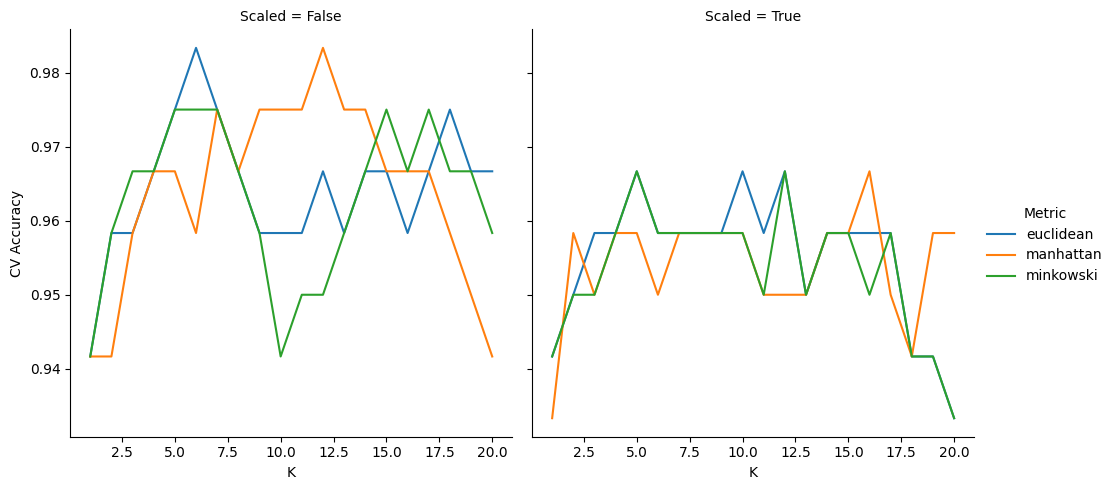

Cấu hình tốt nhất: {'Scaled': False, 'Metric': 'euclidean', 'K': 6, 'CV Accuracy': 0.9833333333333334}
Accuracy: 0.9666666666666667
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.91      1.00      0.95        10
           2       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



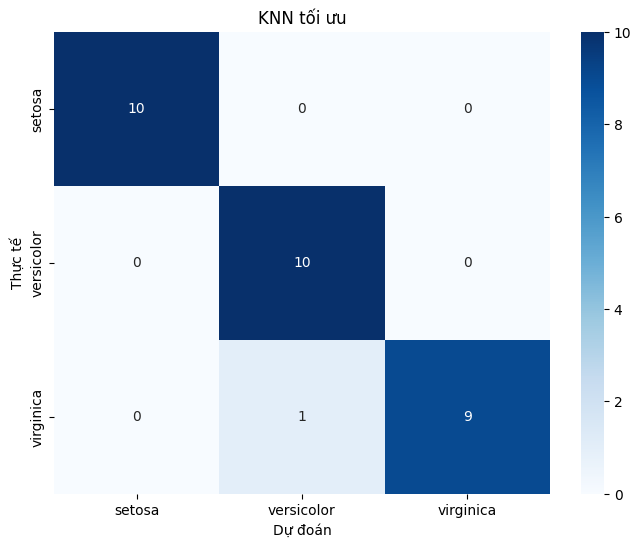

In [2]:
iris = datasets.load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
rows = []
for scaled in [False, True]:
    for metric in ['euclidean', 'manhattan', 'minkowski']:
        for k in range(1, 21):
            knn = KNeighborsClassifier(n_neighbors=k, metric=metric, p=3 if metric=='minkowski' else 2)
            model = make_pipeline(StandardScaler(), knn) if scaled else knn
            cv = cross_val_score(model, X_train, y_train, cv=5).mean()
            rows.append([scaled, metric, k, cv])
results = pd.DataFrame(rows, columns=['Scaled','Metric','K','CV Accuracy'])
display(results.sort_values('CV Accuracy', ascending=False))
sns.relplot(data=results, x='K', y='CV Accuracy', hue='Metric', col='Scaled', kind='line'); plt.show()
best = results.loc[results['CV Accuracy'].idxmax()]
print('Cấu hình tốt nhất:', best.to_dict())
knn = KNeighborsClassifier(n_neighbors=int(best.K), metric=best.Metric, p=3 if best.Metric=='minkowski' else 2)
model = make_pipeline(StandardScaler(), knn) if best.Scaled else knn
model.fit(X_train,y_train)
evaluate(model,X_test,y_test,iris.target_names,'KNN tối ưu')

 Bài 2: KNN hồi quy Boston Housing
`load_boston` đã bị loại khỏi sklearn mới; dùng đúng dữ liệu Boston qua OpenML (cần Internet).

,K,MSE,R2
0,3,19.404281,0.735398
1,5,20.605529,0.719017
2,7,23.415496,0.680700
3,9,24.009424,0.672601


K có MSE thấp nhất: 3


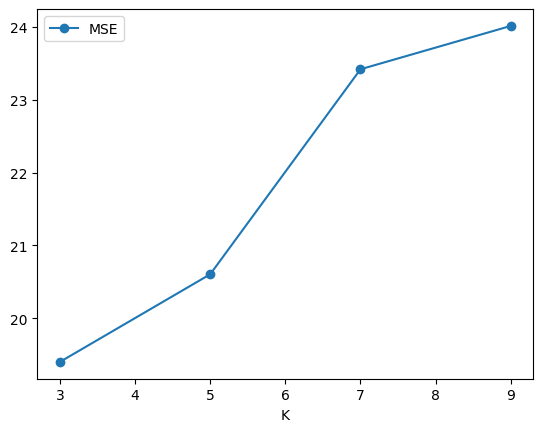

In [3]:
from sklearn.datasets import fetch_openml
boston = fetch_openml(data_id=531, as_frame=True)
X = boston.data.astype(float)
y = boston.target.astype(float)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(X,y,test_size=0.2,random_state=42)
rows=[]
for k in [3,5,7,9]:
    model=make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=k))
    model.fit(Xh_train,yh_train)
    pred=model.predict(Xh_test)
    rows.append([k,mean_squared_error(yh_test,pred),r2_score(yh_test,pred)])
results=pd.DataFrame(rows,columns=['K','MSE','R2'])
display(results)
print('K có MSE thấp nhất:',results.loc[results.MSE.idxmin(),'K'])
results.plot(x='K',y='MSE',marker='o'); plt.show()

Bài 3: SVM Iris với nhiều tỷ lệ chia

,Train,Test,Accuracy
0,0.9,0.1,0.933333
1,0.8,0.2,0.966667
2,0.7,0.3,0.933333
3,0.6,0.4,0.950000


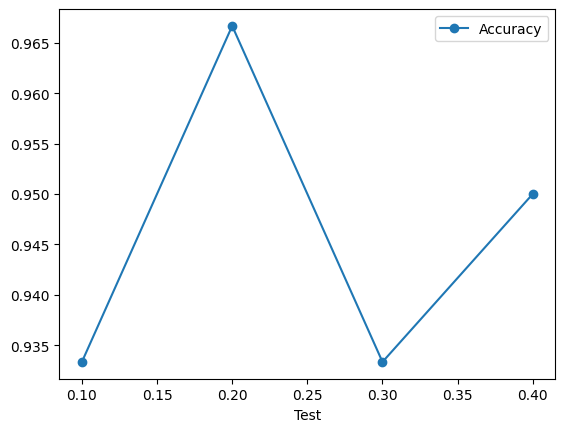

Tỷ lệ có accuracy cao nhất trong thử nghiệm: {'Train': 0.8, 'Test': 0.2, 'Accuracy': 0.9666666666666667}


In [4]:
iris=datasets.load_iris()
rows=[]
for ratio in [0.1,0.2,0.3,0.4]:
    X_train,X_test,y_train,y_test=train_test_split(iris.data,iris.target,test_size=ratio,random_state=42,stratify=iris.target)
    model=make_pipeline(StandardScaler(),SVC(kernel='rbf'))
    model.fit(X_train,y_train)
    rows.append([1-ratio,ratio,model.score(X_test,y_test)])
results=pd.DataFrame(rows,columns=['Train','Test','Accuracy'])
display(results)
results.plot(x='Test',y='Accuracy',marker='o'); plt.show()
print('Tỷ lệ có accuracy cao nhất trong thử nghiệm:',results.loc[results.Accuracy.idxmax()].to_dict())

 Bài 4: SVR Boston Housing (linear, rbf)

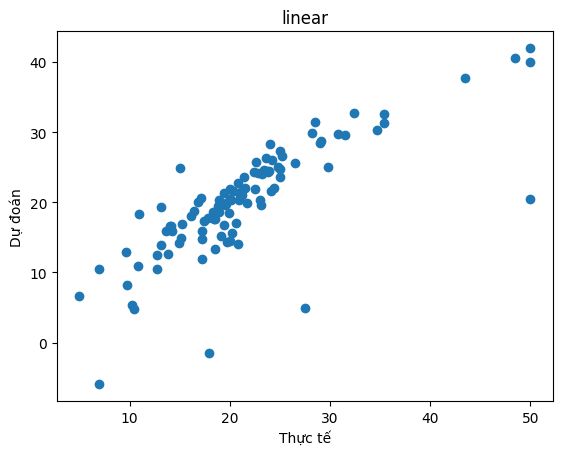

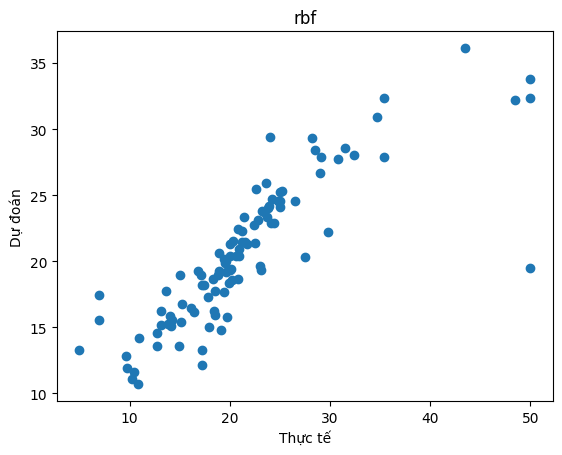

,Kernel,MSE,R2
0,linear,28.918523,0.605659
1,rbf,25.668540,0.649977


Kernel có MSE thấp nhất: rbf


In [5]:
rows=[]
for kernel in ['linear','rbf']:
    model=make_pipeline(StandardScaler(),SVR(kernel=kernel))
    model.fit(Xh_train,yh_train)
    pred=model.predict(Xh_test)
    rows.append([kernel,mean_squared_error(yh_test,pred),r2_score(yh_test,pred)])
    plt.scatter(yh_test,pred); plt.xlabel('Thực tế'); plt.ylabel('Dự đoán'); plt.title(kernel); plt.show()
results=pd.DataFrame(rows,columns=['Kernel','MSE','R2']); display(results)
print('Kernel có MSE thấp nhất:',results.loc[results.MSE.idxmin(),'Kernel'])

## Về nhà – Bài 1: So sánh kernel SVM trên Breast Cancer

,Kernel,Accuracy
0,linear,0.973684
1,rbf,0.982456
2,poly,0.912281
3,sigmoid,0.929825


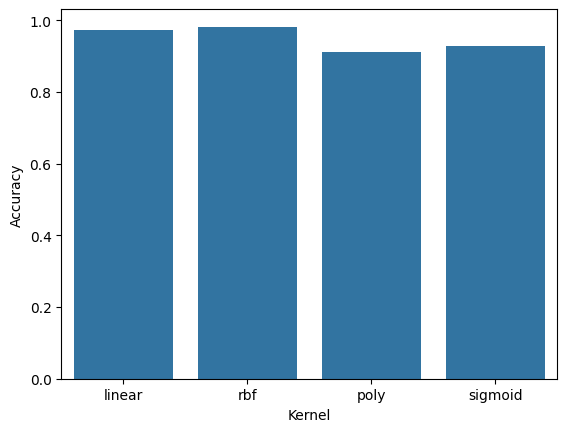

In [6]:
cancer=datasets.load_breast_cancer()
X_train,X_test,y_train,y_test=train_test_split(cancer.data,cancer.target,test_size=0.2,random_state=42,stratify=cancer.target)
rows=[]
for kernel in ['linear','rbf','poly','sigmoid']:
    model=make_pipeline(StandardScaler(),SVC(kernel=kernel))
    model.fit(X_train,y_train)
    rows.append([kernel,model.score(X_test,y_test)])
results=pd.DataFrame(rows,columns=['Kernel','Accuracy']); display(results)
sns.barplot(data=results,x='Kernel',y='Accuracy'); plt.show()

Bài 2: GridSearchCV tìm siêu tham số SVM
CV chỉ sử dụng tập huấn luyện để tránh rò rỉ dữ liệu.

Tham số tối ưu: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
CV Accuracy: 0.9802197802197803
Accuracy: 0.9824561403508771
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



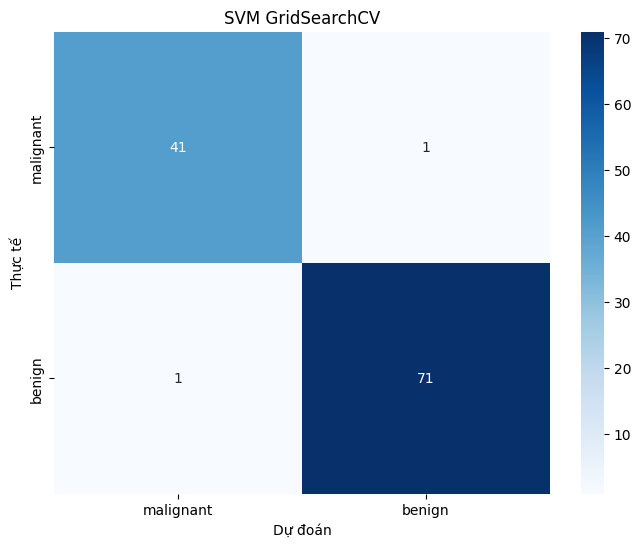

In [7]:
model=make_pipeline(StandardScaler(),SVC())
params={'svc__kernel':['linear','rbf','poly','sigmoid'],'svc__C':[0.1,1,10,100],'svc__gamma':['scale','auto',0.01,0.1]}
grid=GridSearchCV(model,params,cv=5,scoring='accuracy',n_jobs=-1)
grid.fit(X_train,y_train)
print('Tham số tối ưu:',grid.best_params_)
print('CV Accuracy:',grid.best_score_)
evaluate(grid.best_estimator_,X_test,y_test,cancer.target_names,'SVM GridSearchCV')

 Bài 3: KNN và SVM trên Digits

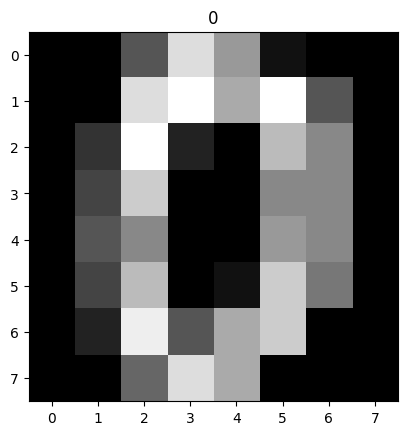

Accuracy: 0.9638888888888889
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  1 36  0  0  0  0  0  0]
 [ 0  0  0  0 34  0  0  2  0  0]
 [ 0  0  0  0  0 36  0  0  0  1]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  1  0 35  0  0]
 [ 0  3  1  0  0  0  0  0 31  0]
 [ 0  0  0  0  1  0  1  1  1 32]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96 

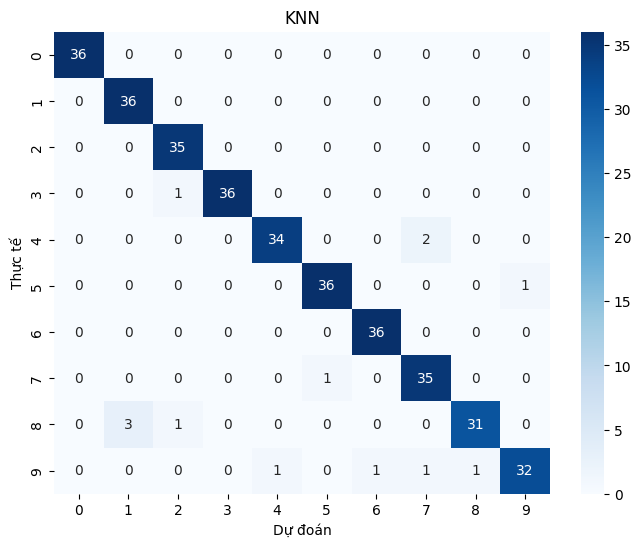

Accuracy: 0.9722222222222222
[[35  0  0  0  0  0  0  0  1  0]
 [ 0 35  0  0  1  0  0  0  0  0]
 [ 0  0 34  0  0  0  0  0  1  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 34  0  2  0]
 [ 0  0  0  0  0  0  0 35  1  0]
 [ 0  1  0  0  0  0  0  0 34  0]
 [ 0  0  0  0  0  0  0  0  3 33]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.97      0.97      0.97        36
           2       1.00      0.97      0.99        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.94      0.97        36
           7       1.00      0.97      0.99        36
           8       0.81      0.97      0.88        35
           9       1.00      0.92      0.96        36

    accuracy                           0.97 

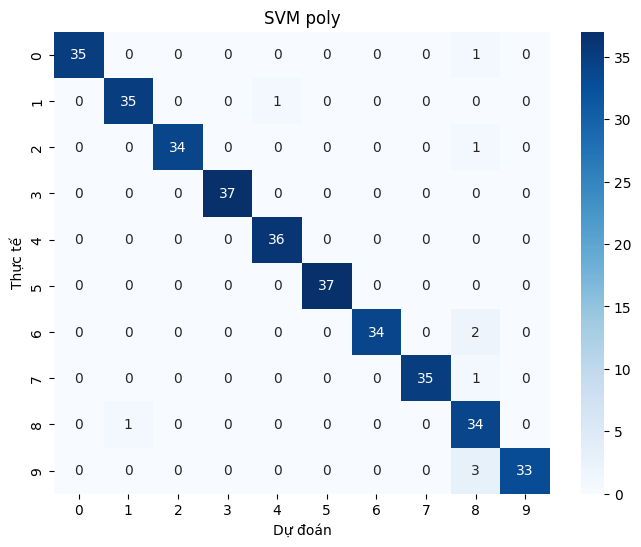

Accuracy: 0.975
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 35  0  0  1  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 35  0  0  1  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  1  0 35  0  0]
 [ 0  2  0  0  1  0  0  0 32  0]
 [ 0  0  0  0  0  0  1  2  0 33]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       1.00      0.91      0.96        35
           9       1.00      0.92      0.96        36

    accuracy                           0.97       360
   

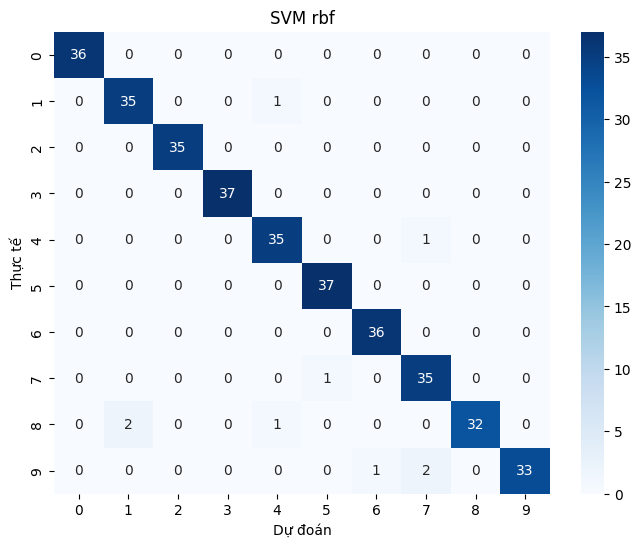

,Model,Accuracy
0,KNN,0.963889
1,SVM poly,0.972222
2,SVM rbf,0.975000


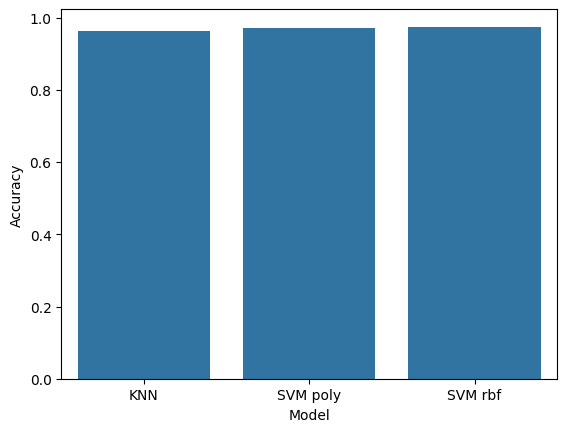

Mô hình có accuracy cao nhất: SVM rbf


In [8]:
digits=datasets.load_digits()
X_train,X_test,y_train,y_test=train_test_split(digits.data,digits.target,test_size=0.2,random_state=42,stratify=digits.target)
plt.imshow(digits.images[0],cmap='gray'); plt.title(str(digits.target[0])); plt.show()
models={'KNN':KNeighborsClassifier(n_neighbors=5),'SVM poly':SVC(kernel='poly'),'SVM rbf':SVC(kernel='rbf')}
rows=[]
for name,estimator in models.items():
    model=make_pipeline(StandardScaler(),estimator)
    model.fit(X_train,y_train)
    rows.append([name,model.score(X_test,y_test)])
    evaluate(model,X_test,y_test,digits.target_names,name)
results=pd.DataFrame(rows,columns=['Model','Accuracy']); display(results)
sns.barplot(data=results,x='Model',y='Accuracy'); plt.show()
print('Mô hình có accuracy cao nhất:',results.loc[results.Accuracy.idxmax(),'Model'])